<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/07_decision_errors_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/07_decision_errors_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3: from a predicted rating to a decision, and where the model goes wrong

Notebook 04 predicts a game's average user rating. A predicted rating is only useful if someone acts on it differently. This notebook:

1. Frames a decision a retailer could make with the prediction (stock and promote a new release, or not) and puts a cost on each kind of mistake, as Session 19's oxygen notebook does.
2. Chooses the cutoff that does best by that cost, using validation rows held out from the training rows, and compares the model with two policies that use no model: act on every game, act on none.
3. Checks how the answer moves when the cost ratio changes.
4. Predicts the rating category directly with a classifier, handling class imbalance, and compares the two approaches.
5. Diagnoses which games the model gets wrong, and why.

The methods are the ones from the course: train/validation/test splits (Session 17), cutoff sweeps with a cost or value per cutoff (Sessions 7 and 19), confusion matrices, precision and recall (Sessions 7 and 10), `class_weight="balanced"` and `DummyClassifier` (Session 19), and decision trees tuned with `GridSearchCV` (Sessions 13 and 19).

**Rows and model are placeholders until Tasks 1 and 10 land.** Section 1 uses notebook 04's rows (games with a missing input dropped) and section 2 uses notebook 04's tuned regression tree, the best model so far. Each is set in one cell, so re-running on Task 1's rows or Task 10's final model means changing that cell and running all.

In [1]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Imports; reviewed and edited by Andrew Reicin.
# --- Andrew Reicin: Task 3, turning predicted ratings into a decision with error costs, and diagnosing the model's errors ---
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score, ConfusionMatrixDisplay

# Figures go to the repository's figures folder when run inside the repository, otherwise next to the notebook.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

## 1. Rows and split

Same loading cell, rows and 70/30 split (random state 1) as notebook 04, so every number here is comparable with it.

In [2]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Load data and define the rows; reviewed and edited by Andrew Reicin.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")

# ROWS: notebook 04's rows, games with every input known. Replace with Task 1's choice on missing values once it is posted.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
data = games.dropna(subset=numeric_cols + ["boardgamemechanic", "boardgamecategory", "average"]).reset_index(drop=True)

train_df, test_df = train_test_split(data, test_size=0.3, random_state=1)
y_train = train_df["average"]
y_test = test_df["average"]
print("games used:", len(data), "| training rows:", len(train_df), "| test rows:", len(test_df))

games used: 17982 | training rows: 12587 | test rows: 5395


In [3]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Build the inputs exactly as notebook 04 does; reviewed and edited by Andrew Reicin.
# The 20 most common mechanics and 15 most common categories, counted on the training rows only.
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index

# Inputs for any set of rows: log10 of the skewed counts and times, plus 0/1 columns for the kept mechanics and categories.
def build_inputs(frame):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top_mech, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=top_cat, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train = build_inputs(train_df)
X_test = build_inputs(test_df)
print("inputs:", X_train.shape[1], "columns")

# Leakage check: none of the post-release columns is an input.
post_release = ["rank", "bayes_average", "users_rated", "owned", "trading", "wanting", "wishing"]
print("post-release columns among the inputs:", [c for c in post_release if c in X_train.columns])

inputs: 43 columns
post-release columns among the inputs: []


## 2. The model

Notebook 04's tuned regression tree (max_depth 10, min_samples_leaf 50, chosen there by 5-fold cross-validation). Re-fitting it here and matching notebook 04's test scores confirms the setup is identical.

In [4]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Fit the model and score it next to the dummy baseline; reviewed and edited by Andrew Reicin.
# MODEL: replace make_model() with Task 10's final model once it is chosen.
def make_model():
    return DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=0)

model = make_model().fit(X_train, y_train)
pred_test = model.predict(X_test)

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Regression tree:  RMSE", round(np.sqrt(mean_squared_error(y_test, pred_test)), 3),
      "| MAE", round(mean_absolute_error(y_test, pred_test), 3), "| R2", round(r2_score(y_test, pred_test), 3))
print("Dummy (mean):     RMSE", round(np.sqrt(mean_squared_error(y_test, dummy_pred)), 3),
      "| MAE", round(mean_absolute_error(y_test, dummy_pred), 3), "| R2", round(r2_score(y_test, dummy_pred), 3))

Regression tree:  RMSE 0.684 | MAE 0.522 | R2 0.425
Dummy (mean):     RMSE 0.903 | MAE 0.709 | R2 -0.0


**Takeaway:** the re-fitted tree matches notebook 04 exactly (test RMSE 0.684, MAE 0.522, R² 0.425, against 0.903 / 0.709 / 0 for the DummyRegressor), so the rows, split and inputs are the same.

## 3. The decision and its costs

**Who decides, and what.** A game retailer chooses, before a new release has any user ratings, whether to stock it deeply and promote it. The model's predicted rating is the only information about quality it has at that point.

**What counts as a success.** A *hit* is a game whose actual average rating is **7.0 or higher**, roughly the top quarter of the catalogue.

**The two mistakes are not equally bad.**
- **Over-predicting (stock a game that is not a hit):** the retailer pays up front for inventory and shelf space, then discounts what does not sell. This is money spent.
- **Under-predicting (pass on a game that is a hit):** the retailer loses the margin it would have made. This is money not earned, and the game can still be ordered later once ratings come in.

We therefore count **a flop as 3 times as costly as a missed hit**. The numbers are hypothetical, like Session 19's 10-to-1 for oxygen sets: what matters is the ratio, and section 6 checks how much the answer depends on it.

In [5]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Hit label and cost function, in the style of Session 19's oxygen_cost; reviewed and edited by Andrew Reicin.
HIT = 7.0   # actual average rating that counts as a hit

# 1 = hit, 0 = not a hit
hit_train = np.where(y_train >= HIT, 1, 0)
hit_test = np.where(y_test >= HIT, 1, 0)
print("share of hits: training rows", round(hit_train.mean(), 3), "| test rows", round(hit_test.mean(), 3))

# Total cost of a stocking decision.
#   stock: 1 if the retailer stocks the game, 0 if it passes;  hit: 1 if the game turned out to be a hit
#   flop_cost: cost of each game stocked that was not a hit;  miss_cost: cost of each hit that was passed over
def decision_cost(stock, hit, flop_cost=3, miss_cost=1):
    stock = np.asarray(stock)
    hit = np.asarray(hit)
    flops = ((stock == 1) & (hit == 0)).sum()     # stocked, not a hit
    missed = ((stock == 0) & (hit == 1)).sum()    # passed, was a hit
    return flop_cost * flops + miss_cost * missed

share of hits: training rows 0.275 | test rows 0.282


## 4. Choosing the cutoff on validation rows

The policy is "stock a game if its predicted rating is at or above a cutoff". The test rows must play no part in choosing the cutoff, and predictions on the rows a model was trained on are too optimistic for it. So, as in Session 17, 30% of the **training** rows are held out as validation rows: the model is fitted on the other 70%, the cutoff is chosen on the validation rows, and only then is the model re-fitted on all training rows and scored on the test rows.

In [6]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Hold out validation rows from the training rows; reviewed and edited by Andrew Reicin.
X_fit, X_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.3, random_state=1)
hit_valid = np.where(y_valid >= HIT, 1, 0)

valid_model = make_model().fit(X_fit, y_fit)
pred_valid = valid_model.predict(X_valid)
print("fitting rows:", len(X_fit), "| validation rows:", len(X_valid))

fitting rows: 8810 | validation rows: 3777


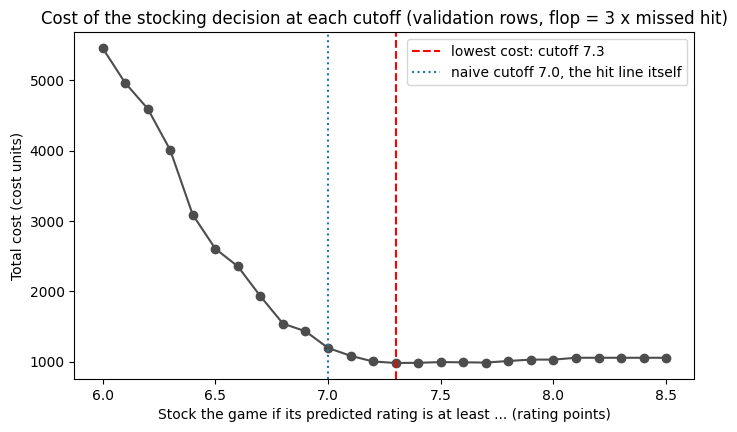

Lowest cost = 980 | best cutoff = 7.3


In [7]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Try every cutoff and record its cost on the validation rows; reviewed and edited by Andrew Reicin.
cutoff_grid = np.round(np.arange(6.0, 8.51, 0.1), 1)
costs = []
for cutoff in cutoff_grid:
    stock = np.where(pred_valid >= cutoff, 1, 0)
    costs.append(decision_cost(stock, hit_valid))

best_idx = np.argmin(costs)
best_cut = cutoff_grid[best_idx]

plt.figure(figsize=(8, 4.5))
plt.plot(cutoff_grid, costs, marker="o", color="0.3")
plt.axvline(x=best_cut, color="red", linestyle="--", label=f"lowest cost: cutoff {best_cut}")
plt.axvline(x=HIT, color="tab:blue", linestyle=":", label=f"naive cutoff {HIT}, the hit line itself")
plt.title("Cost of the stocking decision at each cutoff (validation rows, flop = 3 x missed hit)")
plt.xlabel("Stock the game if its predicted rating is at least ... (rating points)")
plt.ylabel("Total cost (cost units)")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "07_cost_by_cutoff.png"), dpi=300, bbox_inches="tight")
plt.show()
print("Lowest cost =", costs[best_idx], "| best cutoff =", best_cut)

**Takeaway:** on the validation rows the cost is lowest at a cutoff of **7.3**, not at 7.0, the hit line itself. Because a flop costs three times a missed hit, the retailer should stock a game only when the model predicts it comfortably above the hit line.

## 5. The model against policies that use no model

Scored once on the test rows, with the cutoff fixed in section 4 and the model re-fitted on all training rows.

In [8]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Compare decision policies on the test rows; reviewed and edited by Andrew Reicin.
stock_model = np.where(pred_test >= best_cut, 1, 0)
stock_naive = np.where(pred_test >= HIT, 1, 0)
stock_all = np.ones(len(hit_test))
stock_none = np.zeros(len(hit_test))

rows = []
for name, stock in [(f"Model, cutoff {best_cut} (chosen)", stock_model), (f"Model, naive cutoff {HIT}", stock_naive),
                    ("Stock every game", stock_all), ("Stock no game", stock_none)]:
    rows.append({"policy": name,
                 "total cost": decision_cost(stock, hit_test),
                 "games stocked": int(stock.sum()),
                 "flops stocked": int(((stock == 1) & (hit_test == 0)).sum()),
                 "hits missed": int(((stock == 0) & (hit_test == 1)).sum()),
                 "precision": precision_score(hit_test, stock, zero_division=0),
                 "recall": recall_score(hit_test, stock)})
policy_table = pd.DataFrame(rows).set_index("policy").sort_values("total cost")
policy_table.round(3)

,total cost,games stocked,flops stocked,hits missed,precision,recall
policy,,,,,,
"Model, cutoff 7.3 (chosen)",1357,485,80,1117,0.835,0.266
Stock no game,1522,0,0,1522,0.000,0.000
"Model, naive cutoff 7.0",1692,1098,317,741,0.711,0.513
Stock every game,11619,5395,3873,0,0.282,1.000


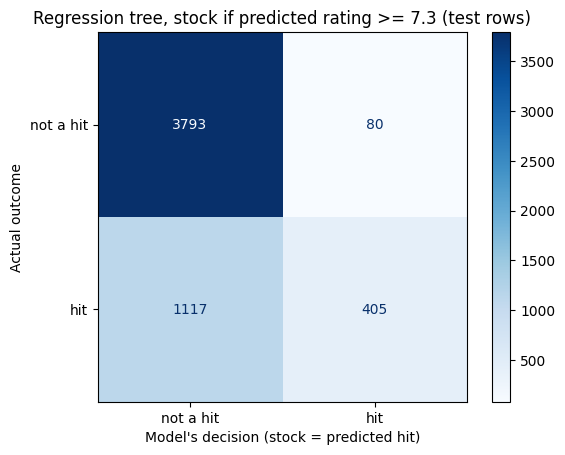

In [9]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Confusion matrix of the chosen policy on the test rows; reviewed and edited by Andrew Reicin.
ConfusionMatrixDisplay.from_predictions(hit_test, stock_model, display_labels=["not a hit", "hit"], cmap="Blues")
plt.title(f"Regression tree, stock if predicted rating >= {best_cut} (test rows)")
plt.xlabel("Model's decision (stock = predicted hit)")
plt.ylabel("Actual outcome")
plt.savefig(os.path.join(FIG_DIR, "07_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** on the test rows the model at cutoff 7.3 costs **1,357**, against 1,522 for stocking nothing and 11,619 for stocking everything, so it beats both no-model policies, but only by about 11% over doing nothing. When it says "stock", it is right 84% of the time (precision 0.84, 405 of 485 games stocked), but it finds only about 1 hit in 4 (recall 0.27). Using the naive cutoff of 7.0 costs **1,692, worse than stocking nothing**: with these costs the cutoff matters as much as the model.

## 6. How much does the answer depend on the cost ratio?

The 3-to-1 ratio is a judgment, so the cutoff is re-chosen on the validation rows under other ratios, and each resulting policy is scored on the test rows against the two no-model policies under the same ratio.

In [10]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Sensitivity of the cutoff and the winning policy to the cost ratio; reviewed and edited by Andrew Reicin.
rows = []
for flop_cost, miss_cost in [(1, 3), (1, 1), (2, 1), (3, 1), (5, 1)]:
    # choose the cutoff on the validation rows under this ratio
    costs_r = [decision_cost(np.where(pred_valid >= c, 1, 0), hit_valid, flop_cost, miss_cost) for c in cutoff_grid]
    cut_r = cutoff_grid[np.argmin(costs_r)]
    # score it on the test rows, next to the two no-model policies
    model_cost = decision_cost(np.where(pred_test >= cut_r, 1, 0), hit_test, flop_cost, miss_cost)
    all_cost = decision_cost(stock_all, hit_test, flop_cost, miss_cost)
    none_cost = decision_cost(stock_none, hit_test, flop_cost, miss_cost)
    rows.append({"flop : missed hit": f"{flop_cost} : {miss_cost}", "chosen cutoff": cut_r, "model": model_cost,
                 "stock every game": all_cost, "stock no game": none_cost,
                 "model saves vs best no-model policy": 1 - model_cost / min(all_cost, none_cost)})
pd.DataFrame(rows).set_index("flop : missed hit").round(3)

,chosen cutoff,model,stock every game,stock no game,model saves vs best no-model policy
flop : missed hit,,,,,
1 : 3,6.6,1987,3873,4566,0.487
1 : 1,7.0,1058,3873,1522,0.305
2 : 1,7.2,1245,7746,1522,0.182
3 : 1,7.3,1357,11619,1522,0.108
5 : 1,7.7,1450,19365,1522,0.047


**Takeaway:** the chosen cutoff rises with the cost of a flop, from 6.6 when a missed hit is the worse mistake to 7.7 when a flop costs five times as much. The model beats both no-model policies under every ratio, but its edge shrinks from 49% to 5% as flops get more expensive, because "stock nothing" becomes hard to beat. The model is most useful to a buyer who fears missing hits more than carrying a few flops.

## 7. Predicting the category directly

The directives suggest trying the regression as classification. Here the target is the same hit / not-hit label, predicted by a decision tree classifier.

- **Imbalance:** only about 27% of games are hits, so a model that never predicts a hit is already about 72% accurate. Accuracy is therefore not used. As in Session 19, `class_weight="balanced"` makes each hit count more in training, and the cutoff on the predicted probability is chosen by the same cost on the same validation rows.
- **Tuning:** max_depth and min_samples_leaf by 5-fold cross-validation on the training rows with `GridSearchCV`, scored by ROC AUC (Session 7): how well the tree ranks hits above non-hits, whatever the cutoff.

In [11]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Dummy classifier: the accuracy trap; reviewed and edited by Andrew Reicin.
dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_train, hit_train)
dummy_stock = dummy_clf.predict(X_test)
print("DummyClassifier (always 'not a hit'): accuracy", round((dummy_stock == hit_test).mean(), 3),
      "| recall", recall_score(hit_test, dummy_stock), "| cost", decision_cost(dummy_stock, hit_test))

DummyClassifier (always 'not a hit'): accuracy 0.718 | recall 0.0 | cost 1522


In [12]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Tune the classifier; reviewed and edited by Andrew Reicin.
param_grid = {"max_depth": [3, 5, 8, 10, 12, 15], "min_samples_leaf": [20, 50, 100, 200, 400]}
search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=0), param_grid,
                      cv=KFold(n_splits=5, shuffle=True, random_state=0), scoring="roc_auc").fit(X_train, hit_train)
print("Best settings:", search.best_params_, "| cross-validated ROC AUC:", round(search.best_score_, 3))
pd.DataFrame(search.cv_results_).pivot(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)

Best settings: {'max_depth': 10, 'min_samples_leaf': 100} | cross-validated ROC AUC: 0.841


param_min_samples_leaf,20,50,100,200,400
param_max_depth,,,,,
3,0.792,0.792,0.792,0.792,0.790
5,0.827,0.827,0.828,0.823,0.809
8,0.836,0.839,0.841,0.829,0.811
10,0.832,0.840,0.841,0.829,0.811
12,0.828,0.839,0.841,0.829,0.811
15,0.827,0.839,0.841,0.829,0.811


**Choosing the classifier's cutoff, including a first attempt kept on purpose.** The probability cutoff is chosen on the same validation rows, with a classifier fitted on the same fitting rows. The first sweep ran from 0.30 to 0.90, and its lowest cost landed on 0.90, the edge of the range. An optimum at the edge can mean the range was too narrow, so a second, finer sweep widens it to 0.98.

First sweep 0.30-0.90: lowest cost at 0.9


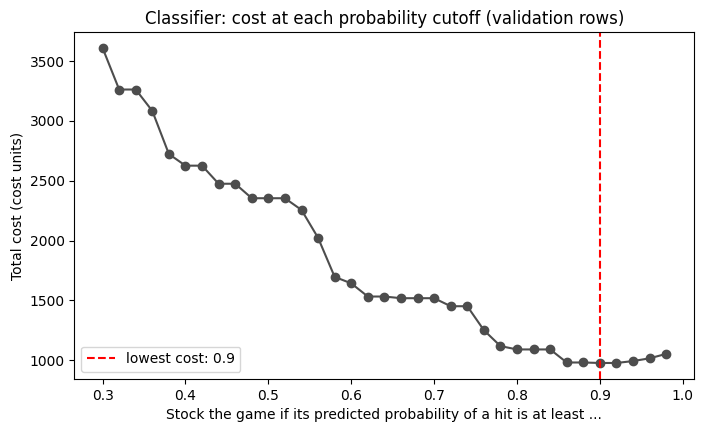

Best probability cutoff = 0.9


In [13]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Choose the probability cutoff on the validation rows; reviewed and edited by Andrew Reicin.
hit_fit = np.where(y_fit >= HIT, 1, 0)
valid_clf = DecisionTreeClassifier(class_weight="balanced", random_state=0, **search.best_params_).fit(X_fit, hit_fit)
prob_valid = valid_clf.predict_proba(X_valid)[:, 1]

# First sweep, 0.30 to 0.90
first_grid = np.round(np.arange(0.30, 0.91, 0.05), 2)
first_costs = [decision_cost(np.where(prob_valid >= c, 1, 0), hit_valid) for c in first_grid]
print("First sweep 0.30-0.90: lowest cost at", first_grid[np.argmin(first_costs)])

# Wider, finer sweep, 0.30 to 0.98
prob_grid = np.round(np.arange(0.30, 0.99, 0.02), 2)
prob_costs = [decision_cost(np.where(prob_valid >= c, 1, 0), hit_valid) for c in prob_grid]
best_p = prob_grid[np.argmin(prob_costs)]

plt.figure(figsize=(8, 4.5))
plt.plot(prob_grid, prob_costs, marker="o", color="0.3")
plt.axvline(x=best_p, color="red", linestyle="--", label=f"lowest cost: {best_p}")
plt.title("Classifier: cost at each probability cutoff (validation rows)")
plt.xlabel("Stock the game if its predicted probability of a hit is at least ...")
plt.ylabel("Total cost (cost units)")
plt.legend()
plt.show()
print("Best probability cutoff =", best_p)

In [14]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Score the classifier once on the test rows, next to the regression approach; reviewed and edited by Andrew Reicin.
clf = search.best_estimator_     # refitted by GridSearchCV on all training rows
stock_clf = np.where(clf.predict_proba(X_test)[:, 1] >= best_p, 1, 0)

rows = []
for name, stock in [(f"Regression tree, rating cutoff {best_cut}", stock_model),
                    (f"Classifier tree, probability cutoff {best_p}", stock_clf), ("Stock no game", stock_none)]:
    rows.append({"policy": name, "total cost": decision_cost(stock, hit_test), "games stocked": int(stock.sum()),
                 "precision": precision_score(hit_test, stock, zero_division=0), "recall": recall_score(hit_test, stock)})
pd.DataFrame(rows).set_index("policy").round(3)

,total cost,games stocked,precision,recall
policy,,,,
"Regression tree, rating cutoff 7.3",1357,485,0.835,0.266
"Classifier tree, probability cutoff 0.9",1377,425,0.835,0.233
Stock no game,1522,0,0.000,0.000


**Takeaway:** the DummyClassifier is 71.8% accurate while finding no hits at all, which is why accuracy is not the metric here. The tuned classifier tree (max_depth 10, min_samples_leaf 100, cross-validated ROC AUC 0.841) has its lowest validation cost at 0.90 even in the wider sweep, so 0.90 is a genuine optimum, not an edge artefact. The cutoff is high because `class_weight="balanced"` pushes every predicted probability of a hit upwards, as Session 19 notes for its death model. On the test rows it stocks 425 games at a cost of 1,377, precision 0.84 and recall 0.23: essentially the same as the regression tree with a rating cutoff (1,357). **Predicting the category directly does not find signal the regression misses**; both models are limited by the same inputs.

## 8. Which games the model gets wrong, and why

Three steps, as section 5.4 of the directives lays out: sanity-check games we understand, compare the games it gets wrong with the ones it gets right, and say what to do about it. *Error* below is predicted minus actual, so positive means the model rated the game too high.

In [15]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 1: sanity-check well-known games in the test rows; reviewed and edited by Andrew Reicin.
check = test_df.copy()
check["predicted"] = pred_test
check["error"] = check["predicted"] - check["average"]
check["abs_error"] = check["error"].abs()

known = ["Pandemic", "Carcassonne", "Ticket to Ride", "Dominion", "Azul", "Codenames", "Splendor", "7 Wonders", "Terraforming Mars",
         "Wingspan", "Scythe", "Risk", "Monopoly", "Clue", "Battleship", "Candy Land", "Chutes and Ladders", "Twilight Struggle", "Agricola", "Jenga"]
cols = ["name", "yearpublished", "maxplaytime", "minage", "n_mechanics", "users_rated", "average", "predicted", "error"]
check[check["name"].isin(known)][cols].sort_values("average").round(2)

,name,yearpublished,maxplaytime,minage,n_mechanics,users_rated,average,predicted,error
397,Battleship,1931.0,30.0,8.0,2.0,9126,4.66,5.85,1.19
10421,Battleship,2014.0,15.0,7.0,1.0,111,5.17,5.84,0.67
286,Jenga,1983.0,20.0,6.0,3.0,12641,5.62,5.84,0.22
5197,Clue,2013.0,45.0,8.0,1.0,394,5.89,5.37,-0.52
5,Ticket to Ride,2004.0,60.0,8.0,7.0,76171,7.41,6.31,-1.10
0,Pandemic,2008.0,45.0,8.0,7.0,108975,7.59,6.61,-0.98
6,Codenames,2015.0,15.0,14.0,4.0,74419,7.60,6.47,-1.13
4,Dominion,2008.0,30.0,13.0,5.0,81561,7.61,6.29,-1.32


**Takeaway:** the model gets the direction right for classic family games (Battleship, Jenga and Clue are predicted below 6, and rated below 6), but it misses well-known modern hits: Ticket to Ride, Pandemic, Codenames and Dominion are all rated about 7.4 to 7.6 and predicted about 6.3 to 6.6. On paper they look like light family games, short and for ages 8 to 14, which is exactly what they are; their quality is not in the inputs.

In [16]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2a: error by actual rating (rounded to the nearest whole point); reviewed and edited by Andrew Reicin.
check["rating, rounded"] = check["average"].round()
by_rating = check.groupby("rating, rounded")[["error", "abs_error"]].mean()
by_rating["games"] = check.groupby("rating, rounded")["error"].count()
by_rating.round(3)

,error,abs_error,games
"rating, rounded",,,
1.0,4.779,4.779,1
3.0,2.973,2.973,13
4.0,1.632,1.632,93
5.0,0.733,0.762,591
6.0,0.168,0.405,1996
7.0,-0.272,0.436,2041
8.0,-0.636,0.665,604
9.0,-1.260,1.260,55
10.0,-1.840,1.840,1


In [17]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2b: error for games with few vs many ratings, wargames vs the rest, and by decade; reviewed and edited by Andrew Reicin.
median_ratings = check["users_rated"].median()
check["number of ratings"] = np.where(check["users_rated"] >= median_ratings, f"{median_ratings:.0f} or more", f"fewer than {median_ratings:.0f}")
check["wargame"] = np.where(check["boardgamecategory"].str.contains("Wargame"), "Wargame", "Other")
check["era"] = np.where(check["yearpublished"] < 1970, "before 1970", check["decade"].astype(int).astype(str) + "s")

print(check.groupby("number of ratings")["abs_error"].agg(["mean", "count"]).round(3), "\n")
print(check.groupby("wargame")["abs_error"].agg(["mean", "count"]).round(3), "\n")
print(check.groupby("era")["abs_error"].agg(["mean", "count"]).round(3))

                    mean  count
number of ratings              
150 or more        0.464   2702
fewer than 150     0.580   2693 

          mean  count
wargame              
Other    0.518   4449
Wargame  0.539    946 

              mean  count
era                      
1970s        0.554    193
1980s        0.516    334
1990s        0.573    492
2000s        0.541   1094
2010s        0.500   2708
2020s        0.488    461
before 1970  0.745    113


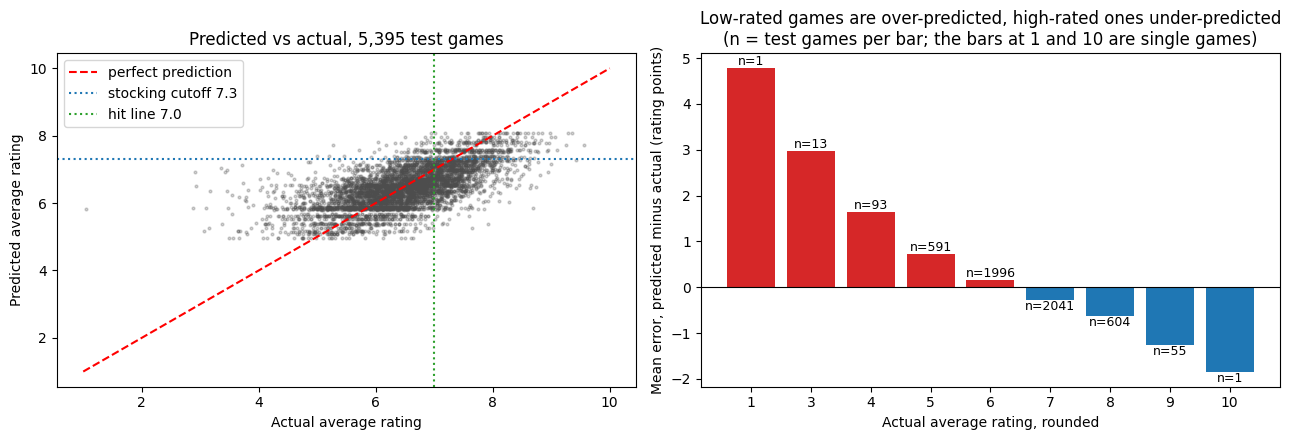

In [18]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: the model pulls every game toward the middle; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(check["average"], check["predicted"], s=4, alpha=0.25, color="0.3")
axes[0].plot([1, 10], [1, 10], color="red", linestyle="--", label="perfect prediction")
axes[0].axhline(y=best_cut, color="tab:blue", linestyle=":", label=f"stocking cutoff {best_cut}")
axes[0].axvline(x=HIT, color="tab:green", linestyle=":", label=f"hit line {HIT}")
axes[0].set_xlabel("Actual average rating")
axes[0].set_ylabel("Predicted average rating")
axes[0].set_title(f"Predicted vs actual, {len(check):,} test games")
axes[0].legend(loc="upper left")

colors = ["tab:red" if v > 0 else "tab:blue" for v in by_rating["error"]]
axes[1].bar(by_rating.index.astype(int).astype(str), by_rating["error"], color=colors)
axes[1].axhline(y=0, color="black", linewidth=0.8)
for i, (err, n) in enumerate(zip(by_rating["error"], by_rating["games"])):
    axes[1].text(i, err, f"n={n}", ha="center", va="bottom" if err > 0 else "top", fontsize=9)
axes[1].set_xlabel("Actual average rating, rounded")
axes[1].set_ylabel("Mean error, predicted minus actual (rating points)")
axes[1].set_title("Low-rated games are over-predicted, high-rated ones under-predicted\n(n = test games per bar; the bars at 1 and 10 are single games)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "07_errors_by_rating.png"), dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2c: the ten largest misses; reviewed and edited by Andrew Reicin.
cols = ["name", "yearpublished", "maxplaytime", "minage", "n_mechanics", "users_rated", "average", "predicted"]
check.sort_values("abs_error", ascending=False)[cols].head(10).round(2)

,name,yearpublished,maxplaytime,minage,n_mechanics,users_rated,average,predicted
12558,Oneupmanship: Mine's Bigger,2013.0,90.0,12.0,5.0,75,1.04,5.82
14669,The Civil War,1991.0,1200.0,12.0,3.0,52,2.91,6.91
15219,New Earth,2016.0,120.0,10.0,5.0,47,3.36,7.05
14658,Warmaster Chess 2000,1998.0,60.0,10.0,1.0,52,2.93,6.49
11272,Big Time Soccer,2016.0,60.0,10.0,2.0,94,3.46,6.99
17040,"Operation Elope, 1918-1919",2001.0,240.0,12.0,3.0,34,3.42,6.92
7259,Nero,2002.0,100.0,12.0,6.0,222,3.71,7.13
10598,Pug You!,2018.0,45.0,16.0,2.0,107,3.17,6.35
1477,Bingo,1530.0,60.0,5.0,3.0,2282,2.88,5.84
13462,Cardiceo,2016.0,60.0,10.0,2.0,64,3.46,6.35


In [20]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2d: the hits the model catches vs the hits it misses; reviewed and edited by Andrew Reicin.
check["hit"] = np.where(check["average"] >= HIT, 1, 0)
check["stocked"] = np.where(check["predicted"] >= best_cut, 1, 0)
hits = check[check["hit"] == 1].copy()
hits["outcome"] = np.where(hits["stocked"] == 1, "hit caught", "hit missed")
print(hits["outcome"].value_counts(), "\n")
hits.groupby("outcome")[["yearpublished", "maxplaytime", "minage", "n_mechanics", "users_rated", "average"]].median().round(1)

outcome
hit missed    1117
hit caught     405
Name: count, dtype: int64 



,yearpublished,maxplaytime,minage,n_mechanics,users_rated,average
outcome,,,,,,
hit caught,2019.0,120.0,13.0,6.0,189.0,7.8
hit missed,2015.0,60.0,12.0,3.0,282.0,7.3


**Takeaway: which games the model gets wrong, and why.**

- **It pulls every game toward the middle.** Games rated about 4 are over-predicted by 1.6 points on average, games rated about 9 under-predicted by 1.3; only around 6 and 7, where most games sit, is the average error near zero. The ten largest misses are all very poorly rated games (1.0 to 3.7) predicted at 5.8 to 7.1: their play time, age, player count and mechanics look like those of an ordinary game.
- **Games with few ratings are harder.** Mean absolute error is 0.58 for games with fewer than 150 ratings and 0.46 for the rest. Their average rating rests on fewer people, so the target itself is noisier.
- **Old games are harder, wargames are not.** Error is 0.75 for games before 1970 and about 0.50 for games since 2010; wargames (0.54) are close to the rest (0.52).
- **Which hits it catches.** The 405 hits it catches are mostly recent, long, heavy games with many mechanics (median 2019, 120 minutes, 6 mechanics). The 1,117 it misses are shorter, lighter and older (median 2015, 60 minutes, 3 mechanics). The model has learned that heavy, recent games tend to rate well, so it cannot recognise a light game that is also excellent.

**What to do about it.** The inputs describe a game's *format*, not its *quality*, so the model cannot separate a great game from a bad one with the same format. Adding pre-release information about who made the game, such as the designer's or publisher's track record (the `boardgamedesigner` and `boardgamepublisher` columns are known before release), is the most promising next feature. Until then, the model should be used to confirm heavy, recent games rather than to judge light family games, and its predictions for games that will attract few ratings should be treated as rough.

## 9. Summary

- With a flop counted as three times a missed hit, the best policy is to stock a game when its predicted rating is **7.3 or higher**. That beats stocking nothing by about 11% and stocking everything by a wide margin; stocking at the obvious cutoff of 7.0 is worse than stocking nothing.
- The model is precise (84% of games it picks are hits) but finds only about 1 hit in 4. Its edge over doing nothing grows when missed hits are costlier and shrinks to almost nothing when flops are.
- Predicting the hit category directly with a balanced classifier gives the same result, so the limit is the inputs, not the method.
- The model pulls ratings toward the middle and misses light, popular games, because the inputs describe a game's format rather than its quality.

**Notes.** Every cutoff was chosen on validation rows held out from the training rows; the test rows were scored once. Rows and model follow notebook 04 until Task 1's missing-value choice and Task 10's final model are in, then this notebook re-runs on them by changing the rows cell in section 1 and `make_model()` in section 2. Figures are saved to `figures/` with the prefix `07_`.